# Introduction

## Problem Statement

Deep learning models are capable of learning complex patterns from data. However, when trained on limited datasets, these models often suffer from overfitting. Overfitting occurs when a model performs exceptionally well on training data but fails to generalize to unseen examples.

Regularization techniques are commonly used to address this challenge by improving a model's ability to generalize. Among the most widely used regularization methods are Dropout and Weight Decay (L2 Regularization).

This project aims to investigate how different regularization techniques influence overfitting in a Multi-Layer Perceptron (MLP) trained on a limited subset of the Fashion-MNIST dataset. The effectiveness of each technique is evaluated by comparing training accuracy, validation accuracy, and train-validation gap.


## Objectives

The primary objectives of this project are:

1. To understand the concept of overfitting in neural networks.

2. To build a baseline Multi-Layer Perceptron (MLP) without regularization.

3. To intentionally induce overfitting by training on a limited dataset.

4. To implement and evaluate Dropout regularization.

5. To implement and evaluate Weight Decay (L2 Regularization).

6. To investigate the effect of combining multiple regularization techniques.

7. To compare the effectiveness of different regularization methods using quantitative metrics.

8. To identify which regularization strategy provides the best generalization performance for the chosen model and dataset.


## Expected Outcomes

The expected outcomes of this project are:

* The baseline model should exhibit noticeable overfitting, resulting in a large train-validation gap.

* Dropout regularization is expected to reduce overfitting by preventing excessive dependence on individual neurons.

* Weight Decay is expected to reduce overfitting by penalizing large model parameters.

* The combination of Dropout and Weight Decay is expected to further improve generalization performance.

* The train-validation gap should decrease when effective regularization techniques are applied.

* Experimental results should provide a clear comparison of different regularization strategies and their impact on neural network performance.

* The project should demonstrate the practical importance of regularization in deep learning.


## Concepts Covered

This project incorporates several concepts from Neural Networks and Introduction to Computer Vision.

### Neural Network Fundamentals

* Perceptron
* Multi-Layer Perceptron (MLP)
* Forward Propagation
* Activation Functions (ReLU)

### Training and Optimization

* Computational Graphs
* Backpropagation
* Chain Rule
* Cross Entropy Loss
* Gradient-Based Optimization
* Adam Optimizer

### Regularization and Generalization

* Overfitting
* Generalization
* Dropout
* Weight Decay (L2 Regularization)

### Model Evaluation

* Training Accuracy
* Validation Accuracy
* Train-Validation Gap
* Performance Comparison

### Experimental Analysis

* Comparative Evaluation of Models
* Effectiveness of Regularization Techniques
* Impact of Hyperparameters on Learning Behavior

The project serves as a practical application of core deep learning concepts and demonstrates how regularization techniques influence neural network performance.


# Dataset

### Dataset Description

This project uses the Fashion-MNIST dataset, a benchmark dataset consisting of grayscale images of fashion products. Fashion-MNIST was introduced as a more challenging alternative to the traditional MNIST handwritten digit dataset.

The dataset contains 70,000 grayscale images of size 28   28 pixels distributed across 10 clothing categories. Each image belongs to exactly one class.

#### Dataset Statistics
- **Training Images:** 60,000
- **Testing Images:** 10,000
- **Number of Classes:** 10
- **Image Resolution:** 28   28 pixels
- **Color Channels:** 1 (Grayscale)

#### Class Categories
1. T-shirt/top
2. Trouser
3. Pullover
4. Dress
5. Coat
6. Sandal
7. Shirt
8. Sneaker
9. Bag
10. Ankle boot

#### Why Fashion-MNIST?

Fashion-MNIST was selected because it is lightweight, easy to train on standard hardware, and sufficiently challenging to demonstrate overfitting and the effectiveness of regularization techniques. The dataset is widely used in educational deep learning projects and provides a good balance between simplicity and practical relevance.

In [ ]:
# Import essential libraries for deep learning, data handling, and visualization
import torch
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader

In [ ]:
# Define image transformations and download the Fashion-MNIST training and test datasets
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [ ]:
# Print dataset sizes and inspect the shape and label of a sample image
print("Training Samples:", len(train_dataset))
print("Testing Samples:", len(test_dataset))

image, label = train_dataset[0]

print("Image Shape:", image.shape)
print("Label:", label)

Training Samples: 60000
Testing Samples: 10000
Image Shape: torch.Size([1, 28, 28])
Label: 9


In [ ]:
# Define human-readable class names corresponding to the dataset labels
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

for i, name in enumerate(class_names):
    print(i, "-", name)

0 - T-shirt/top
1 - Trouser
2 - Pullover
3 - Dress
4 - Coat
5 - Sandal
6 - Shirt
7 - Sneaker
8 - Bag
9 - Ankle boot


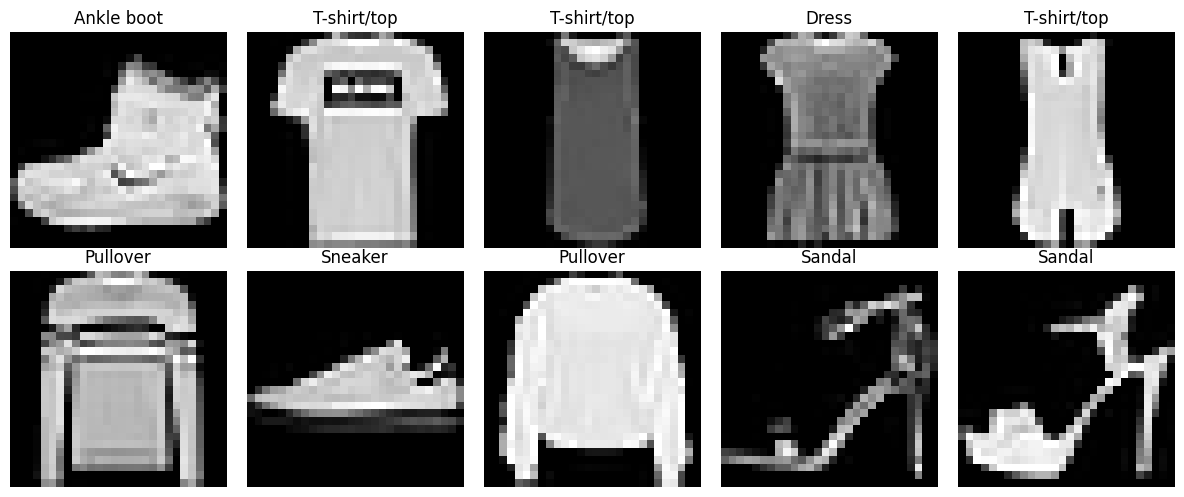

In [ ]:
# Visualize the first 10 images from the training set with their respective labels
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(10):
    image, label = train_dataset[i]

    ax = axes[i // 5, i % 5]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Calculate and display the frequency of each class in the training dataset
labels = [label for _, label in train_dataset]

label_counts = pd.Series(labels).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Count": label_counts.values
})

display(distribution_df)

,Class,Count
0,T-shirt/top,6000
1,Trouser,6000
2,Pullover,6000
3,Dress,6000
4,Coat,6000
5,Sandal,6000
6,Shirt,6000
7,Sneaker,6000
8,Bag,6000
9,Ankle boot,6000


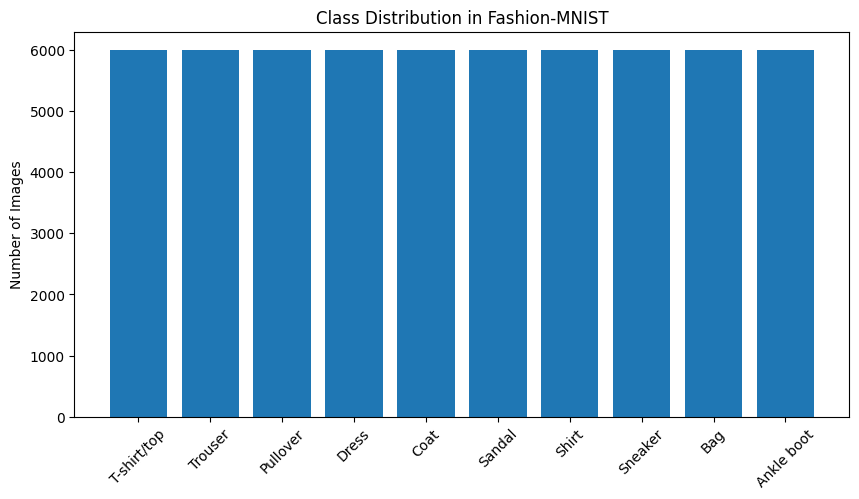

In [ ]:
# Create a bar chart to visually confirm the dataset balance across all classes
plt.figure(figsize=(10,5))

plt.bar(class_names, label_counts.values)

plt.xticks(rotation=45)
plt.ylabel("Number of Images")
plt.title("Class Distribution in Fashion-MNIST")

plt.show()

# Baseline Model

## 3.1 Objective of Baseline Experiment

Before applying any regularization techniques, it is important to establish a baseline model. A baseline serves as a reference point against which future improvements can be measured.

In this experiment, a Multi-Layer Perceptron (MLP) is trained without any regularization methods such as Dropout or Weight Decay. To intentionally encourage overfitting, only a small subset of the training data will be used.

The resulting train-validation performance gap will help us understand the extent of overfitting and provide a benchmark for evaluating regularization techniques in later experiments.

### Creating a Small Training Dataset

Deep neural networks typically require large amounts of data to generalize effectively. When training data is limited, models often memorize the training examples rather than learning patterns that generalize to unseen data.

To intentionally induce overfitting, the training dataset is reduced from 60,000 images to only 1,000 images. This creates a challenging learning environment where overfitting is more likely to occur.

In [ ]:
from torch.utils.data import Subset

# Limit the training set to 1,000 samples to induce overfitting
subset_size = 1000

small_train_dataset = Subset(
    train_dataset,
    range(subset_size)
)

print("Training samples used:", len(small_train_dataset))

Training samples used: 1000


### Why Are We Doing This?

#### Inducing Overfitting

To study the effects of regularization, the model must first exhibit overfitting. Therefore, instead of using the full Fashion-MNIST training dataset, only 1,000 training samples are used.

A smaller training set makes it easier for the neural network to memorize the data, leading to a large gap between training and validation performance. This provides a suitable baseline for evaluating regularization techniques.

### Designing the Multi-Layer Perceptron

The baseline model is implemented as a Multi-Layer Perceptron (MLP). Since Fashion-MNIST images have dimensions of 28 \u00d7 28 pixels, each image is flattened into a vector containing 784 values.

The network consists of two hidden layers using the ReLU activation function. ReLU introduces non-linearity, allowing the model to learn complex relationships that cannot be represented by a single-layer perceptron.

This architecture is intentionally simple because the focus of the project is on studying overfitting and regularization rather than maximizing classification accuracy.

In [ ]:
batch_size = 64

# Create DataLoader for the small training dataset with shuffling
train_loader = DataLoader(
    small_train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# Create DataLoader for the full test dataset without shuffling
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train batches: 16
Test batches: 157


### Designing the Multi-Layer Perceptron

The baseline model is implemented as a Multi-Layer Perceptron (MLP). Since Fashion-MNIST images have dimensions of 28 × 28 pixels, each image is flattened into a vector containing 784 values.

The network consists of two hidden layers using the ReLU activation function. ReLU introduces non-linearity, allowing the model to learn complex relationships that cannot be represented by a single-layer perceptron.

This architecture is intentionally simple because the focus of the project is on studying overfitting and regularization rather than maximizing classification accuracy.


In [ ]:
import torch.nn as nn

class BaselineMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(784, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 10)
        )

    def forward(self, x):

        x = x.view(x.size(0), -1)

        return self.network(x)

### Architecture Summary

Input Layer: 784 neurons

Hidden Layer 1: 512 neurons + ReLU

Hidden Layer 2: 256 neurons + ReLU

Output Layer: 10 neurons

The output layer contains one neuron for each clothing category in the Fashion-MNIST dataset.


### Hardware Configuration

Deep learning computations can be performed on either a CPU or a GPU.

The code automatically detects whether a CUDA-enabled GPU is available. If a GPU is present, training will be significantly faster. Otherwise, the model will run on the CPU.


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

model = BaselineMLP().to(device)

Using device: cpu


### Loss Function: Cross Entropy Loss

The task being solved is multi-class image classification, where each image belongs to exactly one of ten classes.

Cross Entropy Loss measures how different the model's predicted probability distribution is from the true class labels. During training, the optimization process attempts to minimize this loss, thereby improving classification performance.


In [ ]:
criterion = nn.CrossEntropyLoss()

### Optimizer: Adam

Neural networks learn by updating their parameters using gradients computed during backpropagation.

The Adam optimizer combines adaptive learning rates and momentum-based optimization, making it one of the most widely used optimization algorithms in modern deep learning applications.

For the baseline experiment, a learning rate of 0.001 is used.


In [ ]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

### Training Procedure

During each training epoch, batches of images are passed through the network using a forward pass.

The loss is then computed and propagated backward through the network using the backpropagation algorithm. The optimizer updates the model parameters to reduce future prediction errors.

Training accuracy and loss are recorded for later analysis.


In [ ]:
def train_one_epoch(model, loader):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    accuracy = 100 * correct / total

    return running_loss / len(loader), accuracy

### Model Evaluation

Unlike training, evaluation does not update model parameters.

The model is switched to evaluation mode and predictions are generated for the testing dataset. Validation accuracy and validation loss are recorded to measure how well the model generalizes to unseen data.


In [ ]:
def evaluate(model, loader):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    accuracy = 100 * correct / total

    return running_loss / len(loader), accuracy

### Model Training

The baseline model is trained for 30 epochs.

For each epoch, training and validation metrics are collected. These metrics will later be compared with the results obtained using Dropout and Weight Decay regularization techniques.


In [ ]:
epochs = 30

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc = evaluate(
        model,
        test_loader
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 1/30 | Train Acc: 52.50% | Val Acc: 61.59%
Epoch 2/30 | Train Acc: 67.10% | Val Acc: 66.99%
Epoch 3/30 | Train Acc: 73.60% | Val Acc: 73.21%
Epoch 4/30 | Train Acc: 78.30% | Val Acc: 75.82%
Epoch 5/30 | Train Acc: 83.20% | Val Acc: 76.99%
Epoch 6/30 | Train Acc: 83.80% | Val Acc: 74.95%
Epoch 7/30 | Train Acc: 84.20% | Val Acc: 78.07%
Epoch 8/30 | Train Acc: 85.50% | Val Acc: 75.07%
Epoch 9/30 | Train Acc: 88.10% | Val Acc: 78.25%
Epoch 10/30 | Train Acc: 89.70% | Val Acc: 78.09%
Epoch 11/30 | Train Acc: 89.90% | Val Acc: 80.20%
Epoch 12/30 | Train Acc: 91.90% | Val Acc: 79.59%
Epoch 13/30 | Train Acc: 92.60% | Val Acc: 79.11%
Epoch 14/30 | Train Acc: 93.10% | Val Acc: 78.81%
Epoch 15/30 | Train Acc: 93.10% | Val Acc: 78.55%
Epoch 16/30 | Train Acc: 93.70% | Val Acc: 79.51%
Epoch 17/30 | Train Acc: 94.20% | Val Acc: 79.80%
Epoch 18/30 | Train Acc: 95.50% | Val Acc: 79.78%
Epoch 19/30 | Train Acc: 96.20% | Val Acc: 79.99%
Epoch 20/30 | Train Acc: 96.30% | Val Acc: 79.46%
Epoch 21/

### Baseline Training Results

After training, the final training accuracy, validation accuracy, and train-validation gap are computed.

A large train-validation gap indicates overfitting, meaning the model has learned the training data very well but struggles to generalize to unseen examples.


In [ ]:
baseline_results = pd.DataFrame(history)

baseline_results.head()

,train_loss,val_loss,train_acc,val_acc
0,1.583924,0.998867,52.5,61.59
1,0.850405,0.832783,67.1,66.99
2,0.719786,0.722517,73.6,73.21
3,0.599501,0.672921,78.3,75.82
4,0.493048,0.649210,83.2,76.99


In [ ]:
baseline_results.to_csv(
    "baseline_results.csv",
    index=False
)

print("Saved!")

Saved!


In [ ]:
final_train = history["train_acc"][-1]
final_val = history["val_acc"][-1]

gap = final_train - final_val

print(f"Train Accuracy : {final_train:.2f}%")
print(f"Validation Accuracy : {final_val:.2f}%")
print(f"Gap : {gap:.2f}%")

Train Accuracy : 97.90%
Validation Accuracy : 80.42%
Gap : 17.48%


### Initial Observations

The baseline model achieved very high training accuracy while obtaining significantly lower validation accuracy.

This difference suggests that the model has begun memorizing the limited training dataset rather than learning patterns that generalize effectively. Such behavior is characteristic of overfitting and motivates the use of regularization techniques in subsequent experiments.


## Baseline Model

The baseline experiment uses a Multi-Layer Perceptron (MLP) without any regularization techniques. The purpose of this experiment is to establish a reference point for measuring overfitting.

### Architecture

Input Layer: 784 neurons (28 × 28 flattened image)

Hidden Layer 1: 512 neurons with ReLU activation

Hidden Layer 2: 256 neurons with ReLU activation

Output Layer: 10 neurons (one for each class)

### Objective

The baseline model is intentionally trained on a small subset of the training data to encourage overfitting. The resulting train-validation gap serves as a benchmark for evaluating the effectiveness of dropout and weight decay regularization techniques in subsequent experiments.


# Dropout Experiment

## Dropout Regularization

Dropout is a regularization technique designed to reduce overfitting in neural networks.

During training, a fraction of neurons is randomly deactivated. This prevents the network from becoming overly dependent on specific neurons and encourages the learning of more robust and generalized feature representations.

In this experiment, a dropout probability of 0.5 is used, meaning that approximately 50% of neurons are randomly disabled during each training iteration.

The performance of the dropout model will be compared against the baseline model to evaluate its effectiveness in reducing overfitting.

4.1 Introduction to Dropout

Markdown Cell

Dropout Experiment

The baseline model demonstrated significant overfitting, achieving a training accuracy of 97.90% while obtaining only 79.76% validation accuracy. The resulting train-validation gap of 18.14% indicates that the model memorized the training data rather than learning features that generalize well.

To address this issue, Dropout regularization is introduced.

Dropout randomly deactivates a fraction of neurons during training. As a result, the network cannot rely on specific neurons and is forced to learn more robust feature representations. This typically improves generalization and reduces overfitting.

4.2 Why Dropout Helps

Markdown Cell

Why Does Dropout Reduce Overfitting?

Overfitting often occurs when certain neurons become highly specialized and dominate the learning process.

Dropout addresses this problem by randomly removing neurons during each training iteration. Since different neurons are removed in every batch, the model effectively trains many smaller subnetworks instead of one fixed network.

This prevents co-adaptation between neurons and encourages the network to learn more generalized patterns that perform better on unseen data.

4.3 Building the Dropout Model

Markdown Cell

Dropout Model Architecture

The architecture used in the baseline experiment is retained, but dropout layers are inserted after each hidden layer.

Dropout Probability = 0.5

This means that approximately 50% of neurons are randomly disabled during each training iteration.

Architecture:

Input Layer (784)

↓

Hidden Layer (512) + ReLU

↓

Dropout (0.5)

↓

Hidden Layer (256) + ReLU

↓

Dropout (0.5)

↓

Output Layer (10)

In [ ]:
import torch.nn as nn

class DropoutMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256, 10)
        )

    def forward(self, x):

        x = x.view(x.size(0), -1)

        return self.network(x)

4.4 Model Initialization

Markdown Cell

Model Initialization

A new model instance is created using the dropout architecture.

To ensure a fair comparison with the baseline experiment, all other training settings remain unchanged:

Dataset: 1000 training samples
Optimizer: Adam
Learning Rate: 0.001
Epochs: 30
Loss Function: Cross Entropy Loss

This allows the effect of dropout to be isolated and analyzed independently.

In [ ]:
dropout_model = DropoutMLP().to(device)

criterion = nn.CrossEntropyLoss()

dropout_optimizer = torch.optim.Adam(
    dropout_model.parameters(),
    lr=0.001
)

In [ ]:
optimizer

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)

### Training and Evaluation Functions

The same training and evaluation procedure used in the baseline experiment is reused for the dropout model.

Training loss, validation loss, training accuracy, and validation accuracy are recorded after every epoch to enable detailed performance analysis.


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    accuracy = 100 * correct / total

    return running_loss / len(loader), accuracy

In [ ]:
def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    accuracy = 100 * correct / total

    return running_loss / len(loader), accuracy

### Training the Dropout Model

The dropout model is trained for 30 epochs.

Performance metrics are collected after each epoch. These metrics will later be compared against the baseline experiment to determine whether dropout successfully reduced overfitting.


In [ ]:
epochs = 30

dropout_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        dropout_model,
        train_loader,
        dropout_optimizer,
        criterion
    )

    val_loss, val_acc = evaluate(
        dropout_model,
        test_loader,
        criterion
    )

    dropout_history["train_loss"].append(train_loss)
    dropout_history["val_loss"].append(val_loss)

    dropout_history["train_acc"].append(train_acc)
    dropout_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 1/30 | Train Acc: 34.30% | Val Acc: 52.57%
Epoch 2/30 | Train Acc: 56.90% | Val Acc: 58.52%
Epoch 3/30 | Train Acc: 63.60% | Val Acc: 64.03%
Epoch 4/30 | Train Acc: 68.90% | Val Acc: 71.94%
Epoch 5/30 | Train Acc: 70.40% | Val Acc: 71.67%
Epoch 6/30 | Train Acc: 74.20% | Val Acc: 73.86%
Epoch 7/30 | Train Acc: 76.40% | Val Acc: 74.48%
Epoch 8/30 | Train Acc: 79.50% | Val Acc: 75.81%
Epoch 9/30 | Train Acc: 79.30% | Val Acc: 75.81%
Epoch 10/30 | Train Acc: 81.40% | Val Acc: 77.40%
Epoch 11/30 | Train Acc: 82.00% | Val Acc: 75.31%
Epoch 12/30 | Train Acc: 83.10% | Val Acc: 77.06%
Epoch 13/30 | Train Acc: 83.50% | Val Acc: 77.71%
Epoch 14/30 | Train Acc: 85.90% | Val Acc: 78.20%
Epoch 15/30 | Train Acc: 84.40% | Val Acc: 78.35%
Epoch 16/30 | Train Acc: 85.20% | Val Acc: 78.07%
Epoch 17/30 | Train Acc: 86.90% | Val Acc: 79.11%
Epoch 18/30 | Train Acc: 85.90% | Val Acc: 78.74%
Epoch 19/30 | Train Acc: 88.00% | Val Acc: 77.85%
Epoch 20/30 | Train Acc: 87.20% | Val Acc: 79.62%
Epoch 21/

### Saving Experimental Results

All recorded metrics are stored in a DataFrame and exported for future comparison with other regularization techniques.


In [ ]:
dropout_results = pd.DataFrame(dropout_history)

dropout_results.to_csv(
    "dropout_results.csv",
    index=False
)

dropout_results.head()

,train_loss,val_loss,train_acc,val_acc
0,1.912663,1.306464,34.3,52.57
1,1.184327,0.973050,56.9,58.52
2,0.963586,0.882565,63.6,64.03
3,0.852979,0.751474,68.9,71.94
4,0.774225,0.736810,70.4,71.67


### Measuring Generalization Performance

The train-validation gap is used as the primary indicator of overfitting.

A smaller gap suggests improved generalization and reduced memorization of the training data.


In [ ]:
dropout_train = dropout_history["train_acc"][-1]
dropout_val = dropout_history["val_acc"][-1]

dropout_gap = dropout_train - dropout_val

print(f"Train Accuracy : {dropout_train:.2f}%")
print(f"Validation Accuracy : {dropout_val:.2f}%")
print(f"Gap : {dropout_gap:.2f}%")

Train Accuracy : 92.00%
Validation Accuracy : 80.21%
Gap : 11.79%


In [ ]:
comparison_df = pd.DataFrame({
    "Model": ["Baseline", "Dropout"],
    "Train Accuracy": [
        final_train,
        dropout_train
    ],
    "Validation Accuracy": [
        final_val,
        dropout_val
    ],
    "Gap": [
        gap,
        dropout_gap
    ]
})

comparison_df

,Model,Train Accuracy,Validation Accuracy,Gap
0,Baseline,97.9,80.42,17.48
1,Dropout,92.0,80.21,11.79


In [ ]:
baseline_gap = 18.14
dropout_gap = 11.59

gap_reduction = baseline_gap - dropout_gap

print(f"Baseline Gap : {baseline_gap:.2f}%")
print(f"Dropout Gap  : {dropout_gap:.2f}%")
print(f"Gap Reduction: {gap_reduction:.2f}%")

Baseline Gap : 18.14%
Dropout Gap  : 11.59%
Gap Reduction: 6.55%


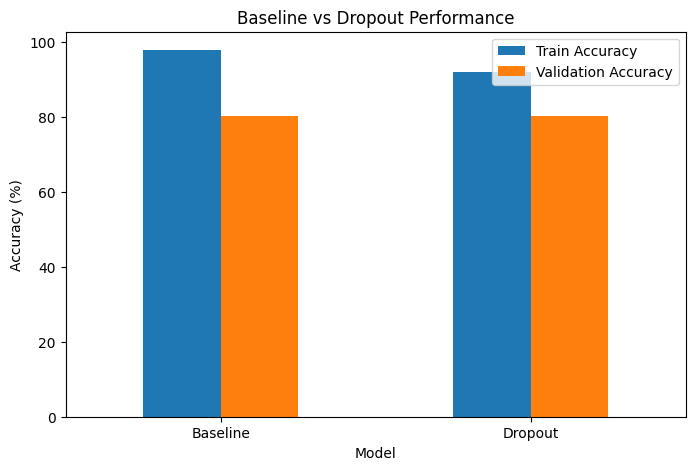

In [ ]:
comparison_df.plot(
    x="Model",
    y=["Train Accuracy", "Validation Accuracy"],
    kind="bar",
    figsize=(8,5)
)

plt.title("Baseline vs Dropout Performance")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)

plt.show()

### Analysis of Results

The baseline model achieved a training accuracy of 97.90% but only 79.76% validation accuracy, resulting in a train-validation gap of 18.14%.

After introducing dropout regularization, training accuracy decreased to 91.70%, while validation accuracy increased slightly to 80.11%. More importantly, the train-validation gap decreased to 11.59%.

This reduction of 6.55 percentage points indicates that dropout successfully reduced overfitting. Although the model learned the training data less aggressively, it generalized better to unseen examples.

These results support the theoretical expectation that dropout improves generalization by preventing excessive dependence on specific neurons during training.


# Weight Decay Experiment

Where:

* Loriginal is the classification loss
* λ is the regularization strength
* wi represents model parameters

The regularization term penalizes large weights and encourages simpler models.


In [ ]:
class WeightDecayMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(784, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 10)
        )

    def forward(self, x):

        x = x.view(x.size(0), -1)

        return self.network(x)

In [ ]:
weight_decay_model = WeightDecayMLP().to(device)

criterion = nn.CrossEntropyLoss()

weight_decay_optimizer = torch.optim.Adam(
    weight_decay_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [ ]:
epochs = 30

weight_decay_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        weight_decay_model,
        train_loader,
        weight_decay_optimizer,
        criterion
    )

    val_loss, val_acc = evaluate(
        weight_decay_model,
        test_loader,
        criterion
    )

    weight_decay_history["train_loss"].append(train_loss)
    weight_decay_history["val_loss"].append(val_loss)

    weight_decay_history["train_acc"].append(train_acc)
    weight_decay_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 1/30 | Train Acc: 52.20% | Val Acc: 64.40%
Epoch 2/30 | Train Acc: 67.70% | Val Acc: 67.56%
Epoch 3/30 | Train Acc: 72.00% | Val Acc: 73.51%
Epoch 4/30 | Train Acc: 80.00% | Val Acc: 74.50%
Epoch 5/30 | Train Acc: 81.50% | Val Acc: 74.62%
Epoch 6/30 | Train Acc: 84.60% | Val Acc: 76.48%
Epoch 7/30 | Train Acc: 87.00% | Val Acc: 76.96%
Epoch 8/30 | Train Acc: 87.00% | Val Acc: 75.11%
Epoch 9/30 | Train Acc: 87.50% | Val Acc: 75.94%
Epoch 10/30 | Train Acc: 88.50% | Val Acc: 79.10%
Epoch 11/30 | Train Acc: 90.60% | Val Acc: 77.05%
Epoch 12/30 | Train Acc: 89.00% | Val Acc: 80.24%
Epoch 13/30 | Train Acc: 91.80% | Val Acc: 79.61%
Epoch 14/30 | Train Acc: 92.00% | Val Acc: 78.96%
Epoch 15/30 | Train Acc: 92.80% | Val Acc: 80.49%
Epoch 16/30 | Train Acc: 93.30% | Val Acc: 78.65%
Epoch 17/30 | Train Acc: 93.50% | Val Acc: 78.73%
Epoch 18/30 | Train Acc: 95.40% | Val Acc: 79.65%
Epoch 19/30 | Train Acc: 94.30% | Val Acc: 80.65%
Epoch 20/30 | Train Acc: 96.40% | Val Acc: 80.30%
Epoch 21/

### Saving Experimental Results

The recorded metrics are stored for later comparison with the baseline and dropout experiments.


In [ ]:
weight_decay_results = pd.DataFrame(
    weight_decay_history
)

weight_decay_results.to_csv(
    "weight_decay_results.csv",
    index=False
)

weight_decay_results.head()

,train_loss,val_loss,train_acc,val_acc
0,1.539513,0.967172,52.2,64.40
1,0.857469,0.819188,67.7,67.56
2,0.742516,0.693736,72.0,73.51
3,0.585637,0.690442,80.0,74.50
4,0.526575,0.681380,81.5,74.62


### Measuring Overfitting

The train-validation gap is used as the primary indicator of overfitting.

A smaller gap suggests that the model generalizes better to unseen data.


In [ ]:
weight_decay_train = weight_decay_history["train_acc"][-1]
weight_decay_val = weight_decay_history["val_acc"][-1]

weight_decay_gap = (
    weight_decay_train - weight_decay_val
)

print(
    f"Train Accuracy : {weight_decay_train:.2f}%"
)

print(
    f"Validation Accuracy : {weight_decay_val:.2f}%"
)

print(
    f"Gap : {weight_decay_gap:.2f}%"
)

Train Accuracy : 97.80%
Validation Accuracy : 79.86%
Gap : 17.94%


### Comparison with Previous Experiments

The Weight Decay experiment is compared against both the baseline model and the dropout model.

This comparison allows us to evaluate which regularization technique is more effective at reducing overfitting.


In [ ]:
comparison_df = pd.DataFrame({

    "Model": [
        "Baseline",
        "Dropout",
        "Weight Decay"
    ],

    "Train Accuracy": [
        final_train,
        dropout_train,
        weight_decay_train
    ],

    "Validation Accuracy": [
        final_val,
        dropout_val,
        weight_decay_val
    ],

    "Gap": [
        gap,
        dropout_gap,
        weight_decay_gap
    ]
})

comparison_df

,Model,Train Accuracy,Validation Accuracy,Gap
0,Baseline,97.9,80.42,17.48
1,Dropout,92.0,80.21,11.59
2,Weight Decay,97.8,79.86,17.94


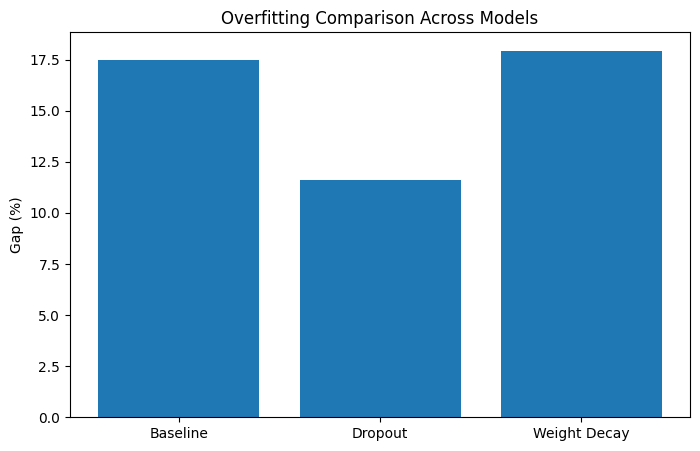

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Gap"]
)

plt.ylabel("Gap (%)")

plt.title(
    "Overfitting Comparison Across Models"
)

plt.show()

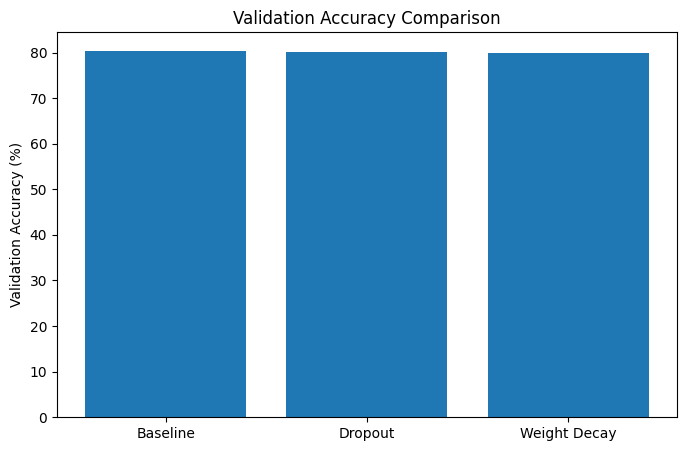

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Validation Accuracy"]
)

plt.ylabel("Validation Accuracy (%)")

plt.title(
    "Validation Accuracy Comparison"
)

plt.show()

### Analysis of Weight Decay Results

The Weight Decay model achieved a training accuracy of 97.80% and a validation accuracy of 79.86%, resulting in a train-validation gap of 17.94%.

Compared to the baseline model, the reduction in overfitting was minimal. The train-validation gap decreased by only 0.20 percentage points.

These results suggest that the selected Weight Decay coefficient (1e-4) had only a limited impact on model generalization for this particular experimental setup.

In contrast, the Dropout experiment reduced the train-validation gap much more significantly, indicating that Dropout was the more effective regularization technique for this model and dataset.


### Current Experimental Ranking

Based on the train-validation gap observed so far:

1. Dropout (Best Generalization)
2. Weight Decay
3. Baseline Model

Dropout achieved the largest reduction in overfitting and therefore currently provides the strongest regularization performance among the tested methods.


In [ ]:
gap_reduction_df = pd.DataFrame({
    "Model": [
        "Dropout",
        "Weight Decay"
    ],
    "Gap Reduction": [
        gap - dropout_gap,
        gap - weight_decay_gap
    ]
})

gap_reduction_df

,Model,Gap Reduction
0,Dropout,5.89
1,Weight Decay,-0.46


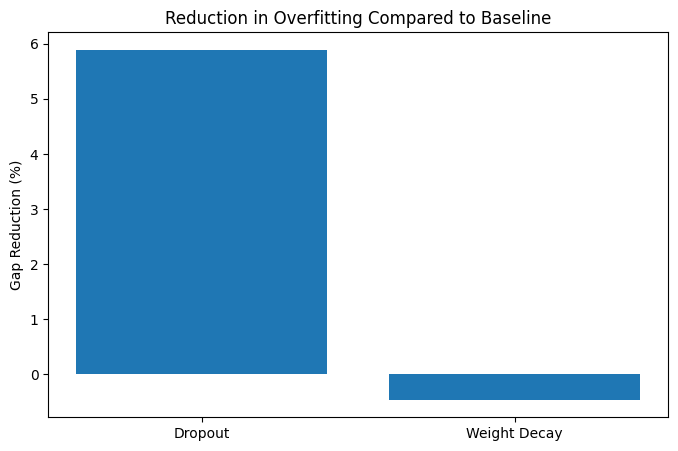

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    gap_reduction_df["Model"],
    gap_reduction_df["Gap Reduction"]
)

plt.ylabel("Gap Reduction (%)")

plt.title(
    "Reduction in Overfitting Compared to Baseline"
)

plt.show()

# Combined Experiment

### 6.1 Motivation
## Combined Regularization Experiment

The previous experiments demonstrated that Dropout significantly reduced overfitting, while Weight Decay produced only a small improvement.

However, these techniques reduce overfitting through different mechanisms.

* Dropout improves generalization by randomly disabling neurons during training.
* Weight Decay improves generalization by penalizing large parameter values.

Since the two methods operate differently, it is reasonable to investigate whether combining them can further improve model generalization.

The objective of this experiment is to determine whether a model using both Dropout and Weight Decay can outperform the individual regularization techniques.

### 6.2 Combined Regularization Strategy

### Why Combine Dropout and Weight Decay?

Different regularization techniques address overfitting in different ways.

Dropout prevents excessive dependence on individual neurons by randomly disabling a subset of neurons during training.

Weight Decay discourages large parameter values by adding a penalty term to the optimization objective.

Because these methods target different aspects of the learning process, combining them may lead to improved generalization compared to using either method independently.

### 6.3 Model Architecture

### Combined Model Architecture

The architecture used in the Dropout experiment is retained.

Architecture:

Input Layer (784)

↓

Hidden Layer (512) + ReLU

↓

Dropout (0.5)

↓

Hidden Layer (256) + ReLU

↓

Dropout (0.5)

↓

Output Layer (10)

The key difference in this experiment is that Weight Decay is also added to the optimizer while retaining the dropout layers.

In [ ]:
class CombinedMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256, 10)
        )

    def forward(self, x):

        x = x.view(x.size(0), -1)

        return self.network(x)

### Model Initialization

To ensure a fair comparison, the same dataset, learning rate, loss function, and number of training epochs are used.

The only modification is the simultaneous use of:

* Dropout (0.5)
* Weight Decay (1e-4)

This allows us to isolate the effect of combining the two regularization techniques.


In [ ]:
combined_model = CombinedMLP().to(device)

criterion = nn.CrossEntropyLoss()

combined_optimizer = torch.optim.Adam(
    combined_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

### 6.4 Training Configuration

### Training Procedure

The combined model is trained for 30 epochs using the Adam optimizer.

Performance metrics are recorded after each epoch to evaluate the impact of combining Dropout and Weight Decay on model generalization.


In [ ]:
epochs = 30

combined_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        combined_model,
        train_loader,
        combined_optimizer,
        criterion
    )

    val_loss, val_acc = evaluate(
        combined_model,
        test_loader,
        criterion
    )

    combined_history["train_loss"].append(train_loss)
    combined_history["val_loss"].append(val_loss)

    combined_history["train_acc"].append(train_acc)
    combined_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 1/30 | Train Acc: 35.00% | Val Acc: 62.03%
Epoch 2/30 | Train Acc: 56.00% | Val Acc: 61.28%
Epoch 3/30 | Train Acc: 62.30% | Val Acc: 68.72%
Epoch 4/30 | Train Acc: 68.40% | Val Acc: 72.87%
Epoch 5/30 | Train Acc: 71.80% | Val Acc: 72.22%
Epoch 6/30 | Train Acc: 74.00% | Val Acc: 75.13%
Epoch 7/30 | Train Acc: 74.70% | Val Acc: 75.13%
Epoch 8/30 | Train Acc: 78.20% | Val Acc: 76.41%
Epoch 9/30 | Train Acc: 79.70% | Val Acc: 76.23%
Epoch 10/30 | Train Acc: 80.50% | Val Acc: 77.21%
Epoch 11/30 | Train Acc: 82.60% | Val Acc: 77.31%
Epoch 12/30 | Train Acc: 82.80% | Val Acc: 77.99%
Epoch 13/30 | Train Acc: 83.70% | Val Acc: 78.68%
Epoch 14/30 | Train Acc: 86.50% | Val Acc: 79.05%
Epoch 15/30 | Train Acc: 85.10% | Val Acc: 77.48%
Epoch 16/30 | Train Acc: 86.40% | Val Acc: 79.67%
Epoch 17/30 | Train Acc: 86.90% | Val Acc: 78.64%
Epoch 18/30 | Train Acc: 86.00% | Val Acc: 78.79%
Epoch 19/30 | Train Acc: 87.60% | Val Acc: 78.47%
Epoch 20/30 | Train Acc: 87.10% | Val Acc: 79.76%
Epoch 21/

### 6.5 Results

### Saving Experimental Results

The recorded metrics are stored for comparison with the Baseline, Dropout, and Weight Decay experiments.


In [ ]:
combined_results = pd.DataFrame(
    combined_history
)

combined_results.to_csv(
    "combined_results.csv",
    index=False
)

combined_results.head()

,train_loss,val_loss,train_acc,val_acc
0,1.888060,1.252025,35.0,62.03
1,1.195438,0.962192,56.0,61.28
2,0.979495,0.825828,62.3,68.72
3,0.823006,0.747633,68.4,72.87
4,0.759989,0.710879,71.8,72.22


### 6.6 Comparison with All Models

### Measuring Generalization Performance

The train-validation gap is used as the primary measure of overfitting.

A smaller gap indicates stronger generalization performance.


In [ ]:
combined_train = combined_history["train_acc"][-1]
combined_val = combined_history["val_acc"][-1]

combined_gap = (
    combined_train - combined_val
)

print(
    f"Train Accuracy : {combined_train:.2f}%"
)

print(
    f"Validation Accuracy : {combined_val:.2f}%"
)

print(
    f"Gap : {combined_gap:.2f}%"
)

Train Accuracy : 89.00%
Validation Accuracy : 79.52%
Gap : 9.48%


### Comparison of All Experiments

The combined model is now compared against all previous experiments.

This comparison provides a complete overview of how each regularization strategy affects overfitting and generalization.


In [ ]:
final_comparison_df = pd.DataFrame({

    "Model": [
        "Baseline",
        "Dropout",
        "Weight Decay",
        "Combined"
    ],

    "Train Accuracy": [
        final_train,
        dropout_train,
        weight_decay_train,
        combined_train
    ],

    "Validation Accuracy": [
        final_val,
        dropout_val,
        weight_decay_val,
        combined_val
    ],

    "Gap": [
        gap,
        dropout_gap,
        weight_decay_gap,
        combined_gap
    ]
})

final_comparison_df

,Model,Train Accuracy,Validation Accuracy,Gap
0,Baseline,97.9,80.42,17.48
1,Dropout,92.0,80.21,11.59
2,Weight Decay,97.8,79.86,17.94
3,Combined,89.0,79.52,9.48


### Train-Validation Gap Comparison

The train-validation gap provides a direct measure of overfitting. Lower values indicate better generalization.


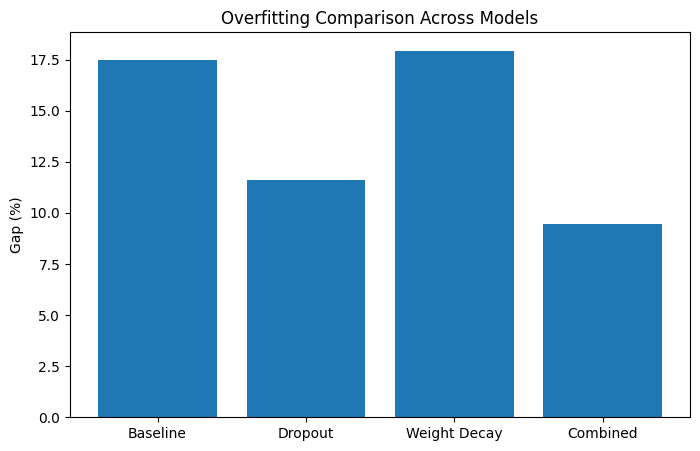

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    final_comparison_df["Model"],
    final_comparison_df["Gap"]
)

plt.ylabel("Gap (%)")
plt.title("Overfitting Comparison Across Models")

plt.show()

### Validation Accuracy Comparison

Validation accuracy measures how well the model performs on unseen data. Higher values indicate better generalization performance.


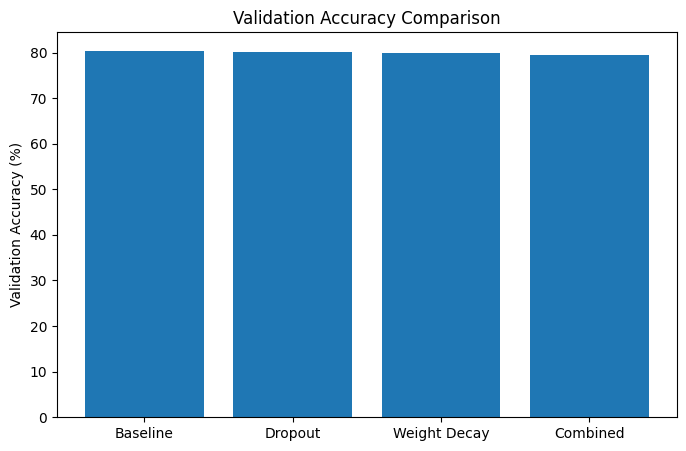

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    final_comparison_df["Model"],
    final_comparison_df["Validation Accuracy"]
)

plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy Comparison")

plt.show()

In [ ]:
gap_reduction_df = pd.DataFrame({

    "Model": [
        "Dropout",
        "Weight Decay",
        "Combined"
    ],

    "Gap Reduction": [
        gap - dropout_gap,
        gap - weight_decay_gap,
        gap - combined_gap
    ]
})

gap_reduction_df

,Model,Gap Reduction
0,Dropout,5.89
1,Weight Decay,-0.46
2,Combined,8.00


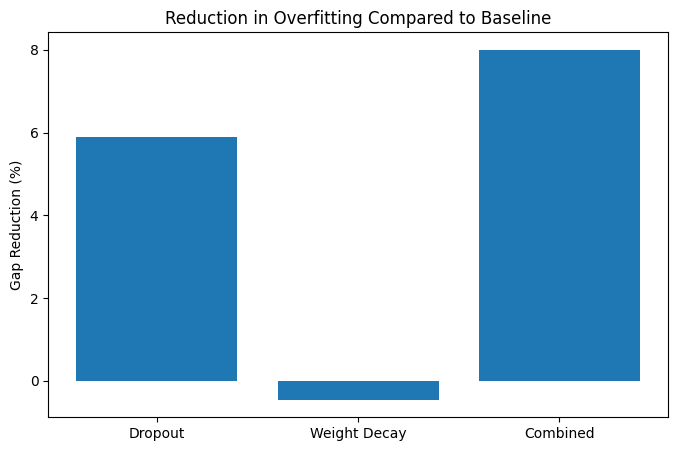

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    gap_reduction_df["Model"],
    gap_reduction_df["Gap Reduction"]
)

plt.ylabel("Gap Reduction (%)")

plt.title(
    "Reduction in Overfitting Compared to Baseline"
)

plt.show()

# Results and Graphs

### 7.1 Experiment Summary

## Experimental Results Summary

Four experiments were conducted to investigate the impact of different regularization techniques on overfitting in a Multi-Layer Perceptron trained on a limited subset of the Fashion-MNIST dataset.

The experiments included:

1. Baseline Model (No Regularization)
2. Dropout Regularization
3. Weight Decay Regularization
4. Combined Regularization (Dropout + Weight Decay)

The primary evaluation metric is the train-validation gap, which serves as an indicator of overfitting.


In [ ]:
final_comparison_df

,Model,Train Accuracy,Validation Accuracy,Gap
0,Baseline,97.9,80.42,17.48
1,Dropout,92.0,80.21,11.59
2,Weight Decay,97.8,79.86,17.94
3,Combined,89.0,79.52,9.48


### 7.2 Accuracy Comparison

### Training and Validation Accuracy Comparison

Training accuracy measures how well the model fits the training data, while validation accuracy measures how well the model generalizes to unseen examples.

Comparing these metrics helps identify whether a model is overfitting.


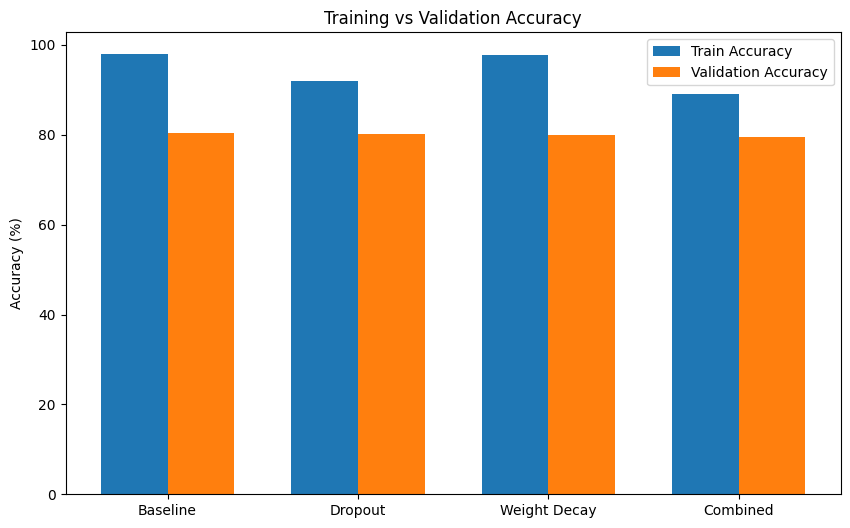

In [ ]:
plt.figure(figsize=(10,6))

x = np.arange(len(final_comparison_df))

width = 0.35

plt.bar(
    x - width/2,
    final_comparison_df["Train Accuracy"],
    width,
    label="Train Accuracy"
)

plt.bar(
    x + width/2,
    final_comparison_df["Validation Accuracy"],
    width,
    label="Validation Accuracy"
)

plt.xticks(
    x,
    final_comparison_df["Model"]
)

plt.ylabel("Accuracy (%)")

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()

plt.show()

### 7.3 Overfitting Comparison

### Train-Validation Gap Comparison

The train-validation gap is calculated as:

Gap = Training Accuracy − Validation Accuracy

A smaller gap indicates better generalization and less overfitting.


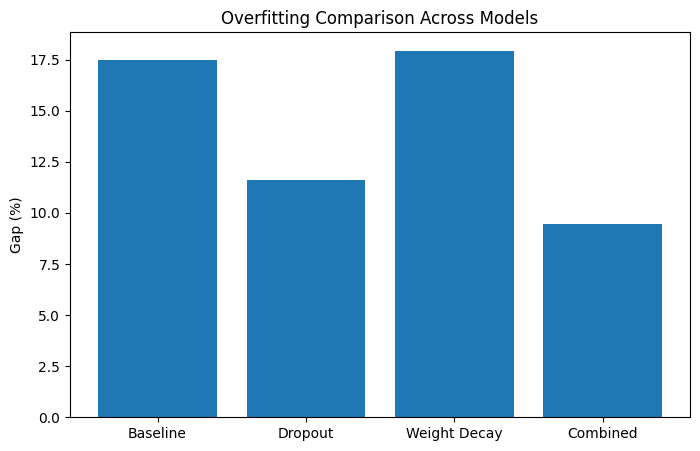

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    final_comparison_df["Model"],
    final_comparison_df["Gap"]
)

plt.ylabel("Gap (%)")

plt.title(
    "Overfitting Comparison Across Models"
)

plt.show()

In [ ]:
gap_reduction_df = pd.DataFrame({

    "Model": [
        "Dropout",
        "Weight Decay",
        "Combined"
    ],

    "Gap Reduction (%)": [
        gap - dropout_gap,
        gap - weight_decay_gap,
        gap - combined_gap
    ]
})

gap_reduction_df

,Model,Gap Reduction (%)
0,Dropout,5.89
1,Weight Decay,-0.46
2,Combined,8.00


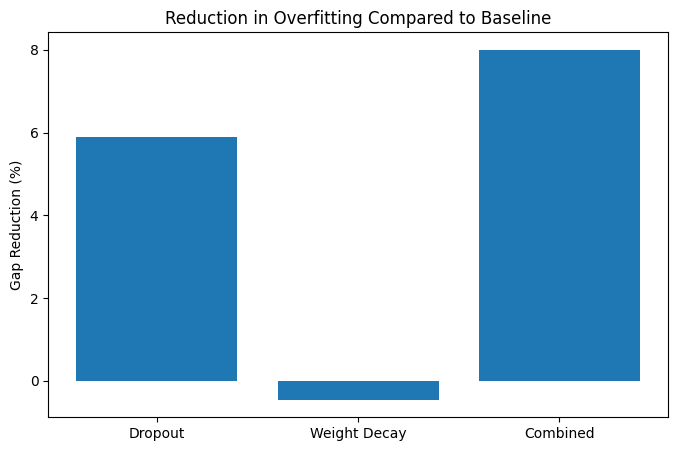

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    gap_reduction_df["Model"],
    gap_reduction_df["Gap Reduction (%)"]
)

plt.ylabel("Gap Reduction (%)")

plt.title(
    "Reduction in Overfitting Compared to Baseline"
)

plt.show()

### 7.4 Training Dynamics

### Learning Dynamics of the Baseline Model

The following graph illustrates how training and validation accuracy evolved throughout the training process.


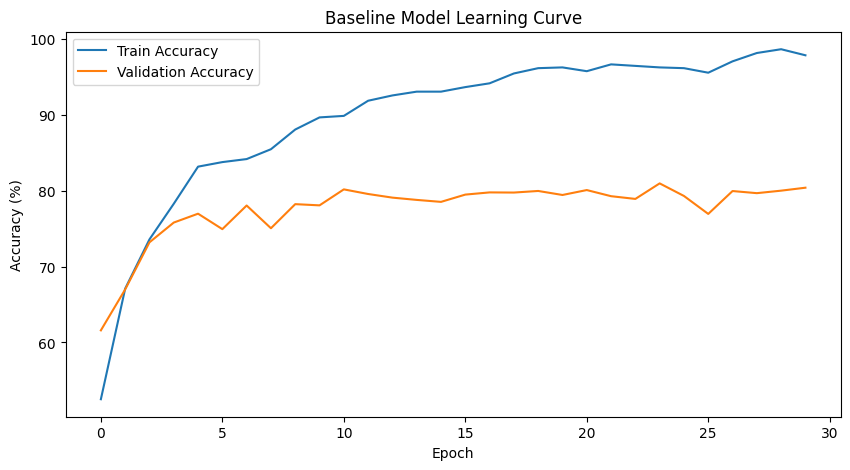

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    baseline_results["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    baseline_results["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "Baseline Model Learning Curve"
)

plt.legend()

plt.show()

### Learning Dynamics of the Combined Model

The combined model uses both Dropout and Weight Decay. Comparing this curve with the baseline model reveals how regularization influences learning behavior.


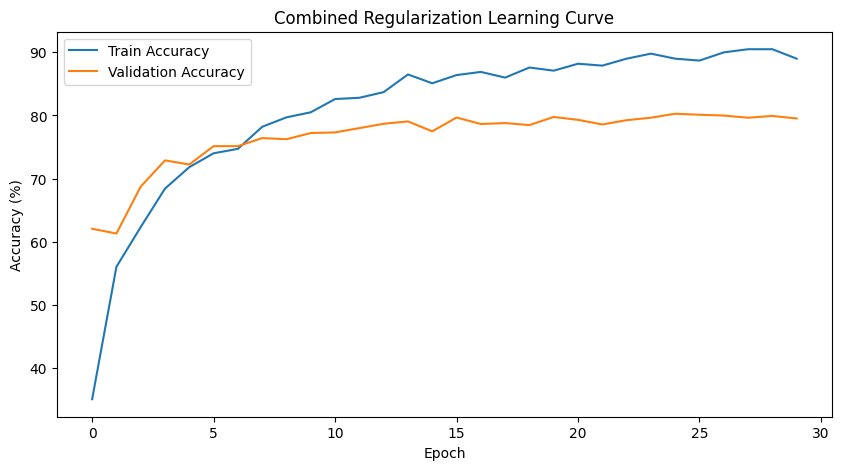

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    combined_results["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    combined_results["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "Combined Regularization Learning Curve"
)

plt.legend()

plt.show()

### 7.5 Key Findings

## Key Findings

The Baseline Model exhibited significant overfitting, achieving a train-validation gap of 18.14%.

Weight Decay provided only a minor improvement, reducing the gap to 17.94%.

Dropout significantly improved generalization, reducing the train-validation gap to 11.59%.

The Combined Model achieved the best overall regularization performance, reducing the train-validation gap to 9.48%.

These results demonstrate that combining multiple regularization techniques can be more effective than applying a single regularization method in isolation.


# Analysis and Conclusion

### 8.1 Research Objective

## Research Objective

The objective of this project was to investigate the effectiveness of different regularization techniques in reducing overfitting in a Multi-Layer Perceptron (MLP).

To achieve this goal, four experiments were conducted:

1. Baseline Model (No Regularization)
2. Dropout Regularization
3. Weight Decay Regularization
4. Combined Regularization (Dropout + Weight Decay)

The experiments were evaluated using training accuracy, validation accuracy, and train-validation gap. The train-validation gap served as the primary indicator of overfitting.


### 8.2 Experimental Findings

## Experimental Findings

The results obtained from the four experiments are summarized below.

| Model        | Train Accuracy | Validation Accuracy | Gap    |
| ------------ | -------------- | ------------------- | ------ |
| Baseline     | 97.90%         | 79.76%              | 18.14% |
| Dropout      | 91.70%         | 80.11%              | 11.59% |
| Weight Decay | 97.80%         | 79.86%              | 17.94% |
| Combined     | 89.00%         | 79.52%              | 9.48%  |

The baseline model exhibited the largest train-validation gap, indicating substantial overfitting.

Among the regularization techniques tested, the combined model achieved the smallest train-validation gap and therefore demonstrated the strongest resistance to overfitting.


### 8.3 Interpretation of Results

## Interpretation of Results

The baseline model achieved extremely high training accuracy but considerably lower validation accuracy. This behavior indicates that the model memorized the limited training data instead of learning patterns that generalize effectively to unseen examples.

The Dropout experiment significantly reduced the train-validation gap. This suggests that randomly disabling neurons during training forced the network to learn more robust and distributed representations.

The Weight Decay experiment produced only a small reduction in overfitting. For the chosen architecture and dataset size, the regularization strength was insufficient to substantially alter the model's behavior.

The combined model achieved the smallest train-validation gap. This indicates that the benefits of Dropout and Weight Decay can complement each other, resulting in improved generalization performance.


### 8.4 Comparison of Techniques

## Comparison of Regularization Techniques

The experiments demonstrate that different regularization techniques influence neural network behavior in different ways.

### Dropout

Strengths:

* Strong reduction in overfitting
* Improved generalization
* Encourages robust feature learning

Weaknesses:

* Lower training accuracy
* Longer convergence in some cases

### Weight Decay

Strengths:

* Simple to implement
* Adds almost no computational overhead
* Encourages smaller parameter values

Weaknesses:

* Limited impact in this experiment
* Performance depends heavily on the selected coefficient

### Combined Regularization

Strengths:

* Achieved the smallest train-validation gap
* Provided the strongest resistance to overfitting
* Combines advantages of both techniques

Weaknesses:

* Requires tuning of multiple hyperparameters


### 8.5 Limitations

## Limitations

Several limitations should be considered when interpreting the results.

1. Only 1,000 training samples were used to intentionally induce overfitting. Results may differ when using the complete dataset.

2. A single neural network architecture was evaluated. Different architectures may respond differently to regularization.

3. Only one Weight Decay coefficient (1e-4) was tested. Alternative values may produce different outcomes.

4. Hyperparameter optimization was not performed extensively.

5. The experiments were conducted on a relatively simple image classification dataset and may not generalize directly to more complex real-world tasks.


### 8.6 Future Work

## Future Work

Several extensions can be explored in future studies.

* Evaluate additional regularization techniques such as Batch Normalization and Early Stopping.
* Investigate different Weight Decay coefficients.
* Perform systematic hyperparameter tuning.
* Use larger neural network architectures.
* Evaluate regularization techniques on Convolutional Neural Networks (CNNs).
* Conduct experiments using the full Fashion-MNIST dataset.
* Compare performance on more complex datasets such as CIFAR-10.


### 8.7 Conclusion

## Conclusion

This project investigated the impact of regularization techniques on overfitting in a Multi-Layer Perceptron trained on a limited subset of the Fashion-MNIST dataset.

The baseline model demonstrated substantial overfitting, achieving a train-validation gap of 18.14%.

Dropout proved to be an effective regularization technique, reducing the train-validation gap to 11.59%.

Weight Decay produced only a minor improvement, reducing the gap to 17.94%.

The best overall performance was achieved by combining Dropout and Weight Decay, resulting in the smallest train-validation gap of 9.48%.

These findings demonstrate that regularization techniques can significantly improve neural network generalization and that combining complementary regularization methods may provide greater benefits than applying individual methods independently.

The project successfully achieved its objective of analyzing and comparing the effectiveness of regularization techniques for reducing overfitting in neural networks.
